# Speech-to-Text from Scratch using PyTorch and CTC

## Objective

This project implements a small end-to-end Speech-to-Text (STT) pipeline
from scratch using PyTorch.

The objective is not to achieve production-level speech recognition
accuracy. Instead, the goal is to demonstrate that the complete STT
pipeline is architecturally correct by overfitting a tiny subset of
LibriSpeech dev-clean.

The pipeline consists of:

Raw Audio
→ Mel-Spectrogram
→ Character Tokenization
→ Padding and Length Tracking
→ 1D CNN Temporal Downsampling
→ Bi-LSTM
→ Linear Classifier
→ CTC Loss
→ Greedy CTC Decoding
→ Evaluation

In [1]:
!pip install -q librosa soundfile

In [2]:
import os
import glob
import tarfile
import random
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import librosa
import librosa.display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

Checking available CPU and GPU

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## Task Constraints

This implementation follows the task constraints:

- No pretrained speech-recognition models or weights.
- No high-level STT APIs such as Whisper, SpeechBrain, NeMo,
  or transformers.pipeline.
- PyTorch is used for model construction and training.
- Librosa is used for Mel-spectrogram feature extraction.
- Only 15 samples are used from LibriSpeech dev-clean.
- A character-level tokenizer with a CTC blank token is used.
- A custom CNN + Bi-LSTM architecture is implemented.
- CTCLoss is used for training.
- A custom greedy CTC decoder is implemented.

In [4]:
# Downloading LibriSpeech

!wget -q --show-progress \
http://www.openslr.org/resources/12/dev-clean.tar.gz \
-O /content/dev-clean.tar.gz

/content/dev-clean. 100%[===================>] 322.27M  16.3MB/s    in 20s     


In [5]:
with tarfile.open("/content/dev-clean.tar.gz", "r:gz") as tar:
    tar.extractall("/content")

print("Extraction complete!")

/tmp/ipykernel_29561/121237281.py:2: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("/content")


Extraction complete!


In [6]:
!ls /content/LibriSpeech      #check extraction

BOOKS.TXT  CHAPTERS.TXT  dev-clean  LICENSE.TXT  README.TXT  SPEAKERS.TXT


finding and filtering the audio file from dev clean directory

In [7]:
audio_files = glob.glob(
    "/content/LibriSpeech/dev-clean/**/*.flac",
    recursive=True
)

print("Total audio files:", len(audio_files))

Total audio files: 2703


## 1. Dataset

I use 15 randomly selected utterances from the LibriSpeech
`dev-clean` subset.

LibriSpeech provides:
- 16 kHz speech recordings
- Corresponding human transcripts
- Variable-duration audio samples

A fixed random seed (`42`) is used so that the same 15 samples
can be reproduced across runs.

The small dataset size is intentional because this task evaluates
whether the STT pipeline can successfully overfit a tiny dataset.

In [8]:
random.seed(42)

selected_files = random.sample(audio_files, 15)

print("Selected samples:", len(selected_files))

for f in selected_files[:5]:
    print(f)

Selected samples: 15
/content/LibriSpeech/dev-clean/1919/142785/1919-142785-0017.flac
/content/LibriSpeech/dev-clean/2803/154320/2803-154320-0004.flac
/content/LibriSpeech/dev-clean/1272/128104/1272-128104-0012.flac
/content/LibriSpeech/dev-clean/2277/149874/2277-149874-0004.flac
/content/LibriSpeech/dev-clean/5694/64029/5694-64029-0030.flac


reading the transcript from metadata of audio

In [9]:
transcript_map = {}

transcript_files = glob.glob(
    "/content/LibriSpeech/dev-clean/**/*.trans.txt",
    recursive=True
)

print("Transcript files:", len(transcript_files))

Transcript files: 97


In [10]:
for txt_file in transcript_files:
    with open(txt_file, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split(" ", 1)

            if len(parts) == 2:
                file_id, transcript = parts
                transcript_map[file_id] = transcript.lower()

print("Total transcripts:", len(transcript_map))

Total transcripts: 2703


In [11]:
for f in selected_files[:5]:
    file_id = os.path.basename(f).replace(".flac", "")
    print(file_id)
    print(transcript_map[file_id])
    print()

1919-142785-0017
the lemon this fruit is a native of asia and is mentioned by virgil as an antidote to poison

2803-154320-0004
much as they had been interested in his dissertation on the pampas or australia his lectures on new zealand fell on cold and indifferent ears

1272-128104-0012
only unfortunately his own work never does get good

2277-149874-0004
his ambition was some day to build a house on them

5694-64029-0030
he was stone dead but i dropped that foot quick



Creating Final 15-Sample Dataset

In [12]:
samples = []

for audio_path in selected_files:

    file_id = os.path.basename(audio_path).replace(".flac", "")

    text = transcript_map[file_id]

    samples.append({
        "audio": audio_path,
        "text": text
    })

df = pd.DataFrame(samples)

df

,audio,text
0,/content/LibriSpeech/dev-clean/1919/142785/191...,the lemon this fruit is a native of asia and i...
1,/content/LibriSpeech/dev-clean/2803/154320/280...,much as they had been interested in his disser...
2,/content/LibriSpeech/dev-clean/1272/128104/127...,only unfortunately his own work never does get...
3,/content/LibriSpeech/dev-clean/2277/149874/227...,his ambition was some day to build a house on ...
4,/content/LibriSpeech/dev-clean/5694/64029/5694...,he was stone dead but i dropped that foot quick
5,/content/LibriSpeech/dev-clean/2428/83705/2428...,and of course i had my expectations and she ha...
6,/content/LibriSpeech/dev-clean/3081/166546/308...,not till the doctor came her doctor who was ha...
7,/content/LibriSpeech/dev-clean/6345/64257/6345...,her only life was that she was lost
8,/content/LibriSpeech/dev-clean/2035/147961/203...,they worked in chicago des moines fort wayne b...
9,/content/LibriSpeech/dev-clean/1993/147149/199...,over the child which yet breathed the father b...


checking audio - load krne k baad

In [13]:
audio_path = df.iloc[0]["audio"]

waveform, sample_rate = sf.read(audio_path)

print("Sample rate:", sample_rate)
print("Waveform shape:", waveform.shape)
print("Duration:", len(waveform) / sample_rate)
print("Text:", df.iloc[0]["text"])

Sample rate: 16000
Waveform shape: (113680,)
Duration: 7.105
Text: the lemon this fruit is a native of asia and is mentioned by virgil as an antidote to poison


playing the sample audio

In [14]:
from IPython.display import Audio, display

display(Audio(waveform, rate=sample_rate))

visualizing audio wave form

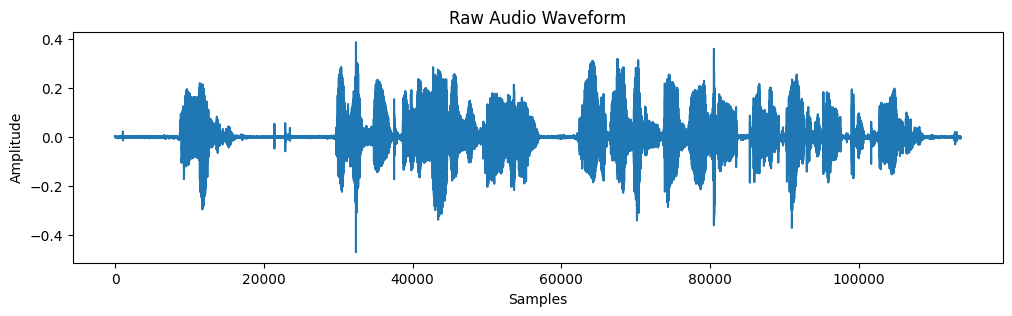

In [15]:
plt.figure(figsize=(12, 3))

plt.plot(waveform)

plt.title("Raw Audio Waveform")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.show()

Raw Audio
      to
Mel-Spectrogram

## 2. Audio Feature Extraction

Raw audio is converted into Mel-spectrogram features.

Configuration:

- Sample rate: 16 kHz
- Number of Mel bins: 80
- FFT size: 400
- Hop length: 160 samples

The resulting feature tensor has the shape:

[Mel features, Time]

For batching, it is later transposed to:

[Time, Mel features]

This representation allows the neural network to process speech as
a temporal sequence rather than directly operating on the raw waveform.

In [16]:
# constants

SAMPLE_RATE = 16000
N_MELS = 80
N_FFT = 400
HOP_LENGTH = 160

# function

def audio_to_mel(audio_path):

    waveform, sr = sf.read(audio_path)

    waveform = waveform.astype(np.float32)

    mel = librosa.feature.melspectrogram(
        y=waveform,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return torch.tensor(
        mel_db,
        dtype=torch.float32
    )

Testing Mel-Spectrogram

In [17]:
# Testing Mel-Spectrogram

mel = audio_to_mel(df.iloc[0]["audio"])

print("Mel shape:", mel.shape)

Mel shape: torch.Size([80, 711])


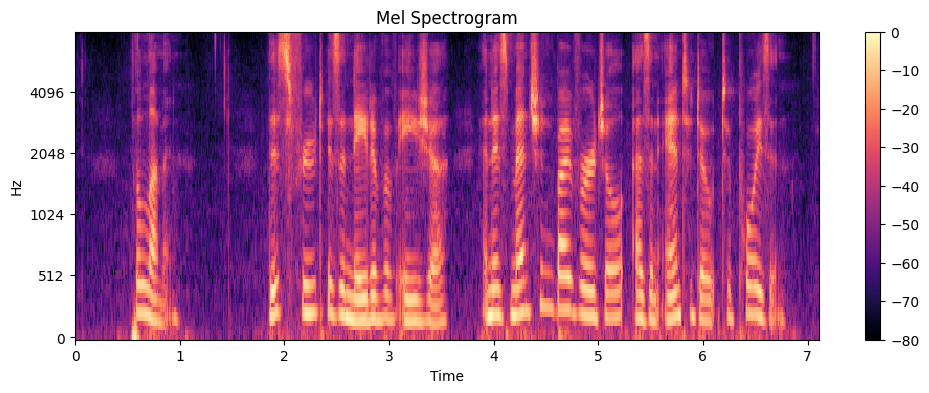

In [18]:
# Visualize

plt.figure(figsize=(12, 4))

librosa.display.specshow(
    mel.numpy(),
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar()
plt.title("Mel Spectrogram")

plt.show()

## 3. Character-Level Tokenization

The transcript is represented using a character-level vocabulary.

Vocabulary:
- a-z
- space
- apostrophe
- CTC blank token

The blank token is required by CTC because it allows the model to
represent alignment gaps and repeated characters between output labels.

The blank token is assigned index 0.

In [19]:
characters = list("abcdefghijklmnopqrstuvwxyz '")

blank_token = "_"

vocab = [blank_token] + characters

char_to_id = {
    char: idx
    for idx, char in enumerate(vocab)
}

id_to_char = {
    idx: char
    for char, idx in char_to_id.items()
}

print(char_to_id)
print("Vocabulary size:", len(vocab))

{'_': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, ' ': 27, "'": 28}
Vocabulary size: 29


In [20]:
# text encoding
def encode_text(text):

    text = text.lower()

    text = "".join(
        char for char in text
        if char in char_to_id
    )

    return torch.tensor(
        [char_to_id[c] for c in text],
        dtype=torch.long
    )

# testing
text = "hello world"

encoded = encode_text(text)

print(text)
print(encoded)

hello world
tensor([ 8,  5, 12, 12, 15, 27, 23, 15, 18, 12,  4])


In [21]:
# text decoding
def simple_decode(ids):

    return "".join(
        id_to_char[int(i)]
        for i in ids
    )

# testing
print(simple_decode(encoded))

hello world


## 4. Dataset and Variable-Length Batching

Speech recordings have different durations, so their Mel-spectrograms
have different numbers of time steps.

The custom Dataset returns:

1. Mel-spectrogram
2. Encoded target sequence
3. Original transcript

The custom `collate_fn` pads the Mel sequences within each batch while
preserving the original sequence lengths.

Two length arrays are maintained:

- `mel_lengths`: original number of Mel time steps
- `target_lengths`: number of characters in each transcript

The target sequences are flattened because PyTorch CTCLoss expects
concatenated targets together with a corresponding `target_lengths` array.

In [22]:
class SpeechDataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        mel = audio_to_mel(row["audio"])

        target = encode_text(row["text"])

        return mel, target, row["text"]

In [23]:
# Creating Dataset

dataset = SpeechDataset(df)

print("Dataset size:", len(dataset))

# testing
mel, target, text = dataset[0]

print("Mel:", mel.shape)
print("Target:", target.shape)
print("Text:", text)

Dataset size: 15
Mel: torch.Size([80, 711])
Target: torch.Size([92])
Text: the lemon this fruit is a native of asia and is mentioned by virgil as an antidote to poison


Collate Function- because every audio has different length

In [24]:
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch):

    mels = [item[0].transpose(0, 1) for item in batch]
    targets = [item[1] for item in batch]
    texts = [item[2] for item in batch]

    mel_lengths = torch.tensor(
        [mel.shape[0] for mel in mels],
        dtype=torch.long
    )

    target_lengths = torch.tensor(
        [len(target) for target in targets],
        dtype=torch.long
    )

    padded_mels = pad_sequence(
        mels,
        batch_first=True
    )

    targets_flat = torch.cat(targets)

    return (
        padded_mels,
        targets_flat,
        mel_lengths,
        target_lengths,
        texts
    )

DataLoader - in batches

In [25]:
loader = DataLoader(
    dataset,
    batch_size=3,           # batch size changing from 5 to 3
    shuffle=True,
    collate_fn=collate_fn
)


#test
batch = next(iter(loader))

mels, targets, mel_lengths, target_lengths, texts = batch

print("Mels:", mels.shape)
print("Targets:", targets.shape)
print("Mel lengths:", mel_lengths)
print("Target lengths:", target_lengths)


Mels: torch.Size([3, 658, 80])
Targets: torch.Size([168])
Mel lengths: tensor([658, 316, 284])
Target lengths: tensor([91, 42, 35])


## 5. Model Architecture

The model uses the following sequence:

Mel-Spectrogram
      ↓
1D CNN
      ↓
Temporal Downsampling
      ↓
2-Layer Bidirectional LSTM
      ↓
Linear Classifier
      ↓
Character Logits

### CNN

Two 1D convolution layers are used along the time dimension.

Each convolution uses:

- Kernel size = 5
- Stride = 2
- Padding = 2

Therefore, each convolution approximately halves the temporal
resolution.

Two stride-2 layers result in approximately 4× temporal
downsampling:

Input time steps → /2 → /2 → approximately /4

The purpose of this downsampling is to reduce the sequence length
before the recurrent layer, reducing computational cost while
retaining the temporal structure needed for speech recognition.

### Bi-LSTM

A 2-layer bidirectional LSTM processes the downsampled sequence.

The hidden size is 128 per direction, resulting in:

128 forward + 128 backward = 256 features per time step.

### Output Layer

A linear layer maps the 256-dimensional Bi-LSTM representation
to the character vocabulary size.

Final output shape:

[Batch, Downsampled Time, Vocabulary Size]

In [26]:
class SpeechToTextModel(nn.Module):

    def __init__(
        self,
        n_mels,
        vocab_size,
        hidden_size=128
    ):

        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv1d(
                n_mels,
                128,
                kernel_size=5,
                stride=2,
                padding=2
            ),

            nn.BatchNorm1d(128),

            nn.ReLU(),

            nn.Conv1d(
                128,
                128,
                kernel_size=5,
                stride=2,
                padding=2
            ),

            nn.BatchNorm1d(128),

            nn.ReLU()
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            bidirectional=True
        )

        self.classifier = nn.Linear(
            hidden_size * 2,
            vocab_size
        )

    def forward(self, x):

        # x: [B, Time, Mel]

        x = x.transpose(1, 2)

        # [B, Mel, Time]

        x = self.cnn(x)

        # [B, 128, downsampled_time]

        x = x.transpose(1, 2)

        # [B, downsampled_time, 128]

        x, _ = self.lstm(x)

        # [B, downsampled_time, 256]

        logits = self.classifier(x)

        # [B, downsampled_time, vocab]

        return logits

In [27]:
# creating model
model = SpeechToTextModel(
    n_mels=N_MELS,
    vocab_size=len(vocab)
).to(device)

print(model)

SpeechToTextModel(
  (cnn): Sequential(
    (0): Conv1d(80, 128, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(128, 128, kernel_size=(5,), stride=(2,), padding=(2,))
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, bidirectional=True)
  (classifier): Linear(in_features=256, out_features=29, bias=True)
)


In [28]:
# ctc loss
ctc_loss = nn.CTCLoss(
    blank=char_to_id["_"],
    zero_infinity=True
)

In [29]:
# optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

## 6. CTC Input Length Calculation

CTC does not operate on the original Mel-spectrogram time length
after temporal downsampling.

The two stride-2 convolution layers change the time dimension.

For a convolution, the output length is calculated using:

output_length =
floor((input_length + 2P - (K - 1) - 1) / S) + 1

where:

K = kernel size = 5
S = stride = 2
P = padding = 2

Because the model contains two such convolution layers, the formula
is applied twice.

The resulting `output_lengths` are passed to `CTCLoss` so that padded
time steps are not treated as valid speech frames.

This is important because each audio sample has a different duration.

In [30]:
# formula
def conv_output_length(
    length,
    kernel_size=5,
    stride=2,
    padding=2
):

    return (
        (length + 2 * padding - (kernel_size - 1) - 1)
        // stride
    ) + 1

def get_output_lengths(lengths):

    lengths = conv_output_length(lengths)
    lengths = conv_output_length(lengths)

    return lengths


## 7. Training with CTC Loss

The model is trained using PyTorch's `CTCLoss`.

The training process is:

1. Mel-spectrogram batch is passed through the model.
2. The model produces character logits.
3. `log_softmax` converts logits into log probabilities.
4. The output is transposed from:

   [Batch, Time, Classes]

   to:

   [Time, Batch, Classes]

   because this is the format expected by CTCLoss.
5. The valid output lengths are calculated after CNN downsampling.
6. Flattened target sequences and target lengths are passed to CTCLoss.
7. Gradients are calculated and the model parameters are updated.

The goal is to intentionally overfit the 15-sample dataset until
the CTC loss approaches zero and the predicted transcripts match
the ground truth.

In [31]:
# Training Loop
def train_one_epoch(model, loader):

    model.train()

    total_loss = 0

    for batch in loader:

        mels, targets, mel_lengths, target_lengths, texts = batch

        mels = mels.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        logits = model(mels)

        # [B, T, C]
        log_probs = F.log_softmax(
            logits,
            dim=-1
        )

        output_lengths = get_output_lengths(
            mel_lengths
        )

        # CTC expects [T, B, C]
        log_probs = log_probs.transpose(0, 1)

        loss = ctc_loss(
            log_probs,
            targets,
            output_lengths,
            target_lengths
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [32]:
# train

EPOCHS = 300

loss_history = []

for epoch in range(EPOCHS):

    loss = train_one_epoch(
        model,
        loader
    )

    loss_history.append(loss)

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch+1:03d} | "
            f"CTC Loss: {loss:.4f}"
        )

Epoch 010 | CTC Loss: 2.9171
Epoch 020 | CTC Loss: 2.8833
Epoch 030 | CTC Loss: 2.7910
Epoch 040 | CTC Loss: 2.6593
Epoch 050 | CTC Loss: 2.4669
Epoch 060 | CTC Loss: 2.1922
Epoch 070 | CTC Loss: 1.8837
Epoch 080 | CTC Loss: 1.4678
Epoch 090 | CTC Loss: 0.9901
Epoch 100 | CTC Loss: 0.8654
Epoch 110 | CTC Loss: 0.4540
Epoch 120 | CTC Loss: 0.2911
Epoch 130 | CTC Loss: 0.2012
Epoch 140 | CTC Loss: 0.1453
Epoch 150 | CTC Loss: 0.1050
Epoch 160 | CTC Loss: 0.0817
Epoch 170 | CTC Loss: 0.1029
Epoch 180 | CTC Loss: 0.0520
Epoch 190 | CTC Loss: 0.0474
Epoch 200 | CTC Loss: 0.0352
Epoch 210 | CTC Loss: 0.0406
Epoch 220 | CTC Loss: 0.0373
Epoch 230 | CTC Loss: 0.0258
Epoch 240 | CTC Loss: 0.0228
Epoch 250 | CTC Loss: 0.0181
Epoch 260 | CTC Loss: 0.2261
Epoch 270 | CTC Loss: 0.1835
Epoch 280 | CTC Loss: 0.0386
Epoch 290 | CTC Loss: 0.0265
Epoch 300 | CTC Loss: 0.0187


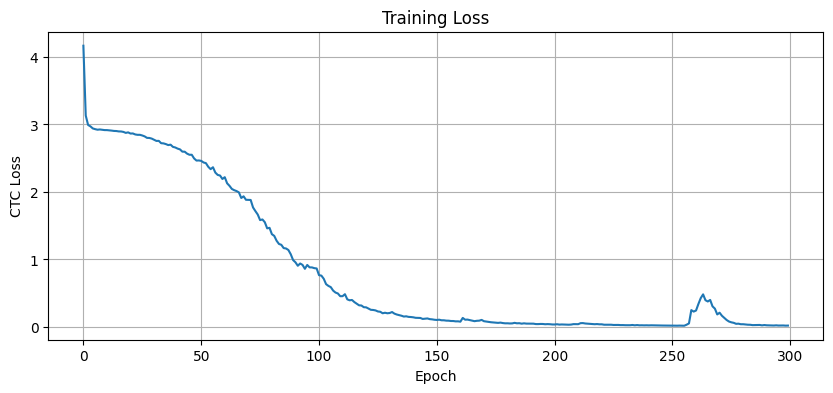

In [33]:
# plot loss
plt.figure(figsize=(10, 4))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("CTC Loss")
plt.title("Training Loss")

plt.grid()

plt.show()

CTC greedy decoder

## 8. Greedy CTC Decoding

The decoder converts model logits into readable text.

The decoding procedure is:

1. Apply argmax over the vocabulary dimension.
2. Restrict each sequence to its valid CTC output length.
3. Collapse consecutive repeated characters.
4. Remove CTC blank tokens.
5. Convert token IDs back to characters.

This produces the final predicted transcript.

No external speech-recognition decoder or pretrained model is used.

In [34]:
#Argmax -> Repeated characters remove -> Blank remove

def greedy_decode(logits, output_lengths):
    predictions = torch.argmax(logits, dim=-1)

    decoded_texts = []

    for sequence, length in zip(predictions, output_lengths):

        sequence = sequence[:length]

        decoded = []
        previous = None

        for token in sequence:
            token = token.item()

            if token == char_to_id["_"]:
                previous = None
                continue

            if token == previous:
                continue

            decoded.append(id_to_char[token])
            previous = token

        decoded_texts.append("".join(decoded))

    return decoded_texts


Testing Predictions

In [35]:
model.eval()

with torch.no_grad():

    for batch in loader:

        mels, targets, mel_lengths, target_lengths, texts = batch

        mels = mels.to(device)

        logits = model(mels)

        output_lengths = get_output_lengths(mel_lengths)

        predictions = greedy_decode(
            logits,
            output_lengths
        )

        for gt, pred in zip(texts, predictions):
            print("GROUND TRUTH :", gt)
            print("PREDICTION    :", pred)
            print("-" * 70)

        break

GROUND TRUTH : not till the doctor came her doctor who was happily in his office in this very building
PREDICTION    : not till the doctor came her doctor who was happily in his office in this very building
----------------------------------------------------------------------
GROUND TRUTH : the lemon this fruit is a native of asia and is mentioned by virgil as an antidote to poison
PREDICTION    : the lemon this fruit is a native of asia and is mentioned by virgil as an antidote to poison
----------------------------------------------------------------------
GROUND TRUTH : and of course i had my expectations and she had hers
PREDICTION    : and of course i had my expectations and she had hers
----------------------------------------------------------------------


In [36]:
# Saving Model

torch.save(
    model.state_dict(),
    "/content/stt_ctc_model.pth"
)

print("Model saved!")

Model saved!


## 9. Evaluation

The final model is evaluated on the same 15 samples used during
training. This is intentional because the assignment's objective is
to demonstrate successful overfitting of a tiny dataset rather than
measure generalization performance.

The evaluation reports:

- Exact Match Accuracy
- Character Error Rate (CER)
- Character-level Edit Distance

### Final Results

- Number of samples: 15
- Exact Match Accuracy: 100.00%
- Average CER: 0.0000
- Character Accuracy: 100.00%

The complete sample-wise predictions are shown in the final evaluation
table below.

In [37]:


#  CHARACTER-LEVEL EDIT DISTANCE


def edit_distance(reference, hypothesis):

    n = len(reference)
    m = len(hypothesis)

    # DP table
    dp = [[0] * (m + 1) for _ in range(n + 1)]

    # Deletions
    for i in range(n + 1):
        dp[i][0] = i

    # Insertions
    for j in range(m + 1):
        dp[0][j] = j

    # Calculate edit distance
    for i in range(1, n + 1):

        for j in range(1, m + 1):

            if reference[i - 1] == hypothesis[j - 1]:
                cost = 0
            else:
                cost = 1

            dp[i][j] = min(
                dp[i - 1][j] + 1,       # deletion
                dp[i][j - 1] + 1,       # insertion
                dp[i - 1][j - 1] + cost # substitution
            )

    return dp[n][m]


# ============================================================
# 2. RUN MODEL ON DATASET
# ============================================================

results = []

model.eval()

with torch.no_grad():

    for batch in loader:

        # Get batch
        mels, targets, mel_lengths, target_lengths, texts = batch

        # Move features to device
        mels = mels.to(device)

        # Model output
        logits = model(mels)

        # Calculate valid CTC output lengths
        output_lengths = get_output_lengths(mel_lengths)

        # Greedy CTC decoding
        predictions = greedy_decode(
            logits,
            output_lengths
        )

        # Compare each sample
        for gt, pred in zip(texts, predictions):

            gt = gt.strip()
            pred = pred.strip()

            exact_match = (gt == pred)

            distance = edit_distance(gt, pred)

            if len(gt) > 0:
                cer = distance / len(gt)
            else:
                cer = 0.0 if len(pred) == 0 else 1.0

            results.append({
                "Ground Truth": gt,
                "Prediction": pred,
                "Exact Match": exact_match,
                "Edit Distance": distance,
                "CER": cer
            })


results_df = pd.DataFrame(results)


exact_match_accuracy = (
    results_df["Exact Match"].mean() * 100
)


average_cer = results_df["CER"].mean()



#  DISPLAY FINAL RESULTS


print("=" * 70)
print("FINAL MODEL EVALUATION")
print("=" * 70)

print(
    f"Number of samples : {len(results_df)}"
)

print(
    f"Exact Match Accuracy : {exact_match_accuracy:.2f}%"
)

print(
    f"Average CER          : {average_cer:.4f}"
)

print(
    f"Character Accuracy   : {(1 - average_cer) * 100:.2f}%"
)

print("=" * 70)

# display predictions
display(results_df)

FINAL MODEL EVALUATION
Number of samples : 15
Exact Match Accuracy : 100.00%
Average CER          : 0.0000
Character Accuracy   : 100.00%


,Ground Truth,Prediction,Exact Match,Edit Distance,CER
0,have you any message for captain bennydeck,have you any message for captain bennydeck,True,0,0.0
1,and of course i had my expectations and she ha...,and of course i had my expectations and she ha...,True,0,0.0
2,much as they had been interested in his disser...,much as they had been interested in his disser...,True,0,0.0
3,he was stone dead but i dropped that foot quick,he was stone dead but i dropped that foot quick,True,0,0.0
4,her only life was that she was lost,her only life was that she was lost,True,0,0.0
5,over the child which yet breathed the father b...,over the child which yet breathed the father b...,True,0,0.0
6,not till the doctor came her doctor who was ha...,not till the doctor came her doctor who was ha...,True,0,0.0
7,only unfortunately his own work never does get...,only unfortunately his own work never does get...,True,0,0.0
8,he asked the handler who was kneading his achi...,he asked the handler who was kneading his achi...,True,0,0.0
9,the lemon this fruit is a native of asia and i...,the lemon this fruit is a native of asia and i...,True,0,0.0


In [38]:

# EXAMPLE PREDICTIONS FOR FINAL REPORT


print("\nFINAL TRANSCRIPTION EXAMPLES")
print("=" * 70)

for i, row in results_df.head(5).iterrows():

    print(f"\nExample {i + 1}")
    print("GROUND TRUTH:")
    print(row["Ground Truth"])

    print("\nPREDICTION:")
    print(row["Prediction"])

    print("\nEXACT MATCH:", row["Exact Match"])
    print("CER:", f"{row['CER']:.4f}")

    print("-" * 70)


FINAL TRANSCRIPTION EXAMPLES

Example 1
GROUND TRUTH:
have you any message for captain bennydeck

PREDICTION:
have you any message for captain bennydeck

EXACT MATCH: True
CER: 0.0000
----------------------------------------------------------------------

Example 2
GROUND TRUTH:
and of course i had my expectations and she had hers

PREDICTION:
and of course i had my expectations and she had hers

EXACT MATCH: True
CER: 0.0000
----------------------------------------------------------------------

Example 3
GROUND TRUTH:
much as they had been interested in his dissertation on the pampas or australia his lectures on new zealand fell on cold and indifferent ears

PREDICTION:
much as they had been interested in his dissertation on the pampas or australia his lectures on new zealand fell on cold and indifferent ears

EXACT MATCH: True
CER: 0.0000
----------------------------------------------------------------------

Example 4
GROUND TRUTH:
he was stone dead but i dropped that foot quick

